**PRÁCTICA 4 - Introducción a los biopotenciales y adquisición de señales ECG y EMG**

Integrantes: 

- Valentina Morales
- Paula García


---

**5.1 Esquema y registro de biopotenciales**

La señal bioeléctrica generada por el cuerpo se capta mediante electrodos desechables de Ag/AgCl, que actúan como transductores: convierten la corriente iónica del tejido en corriente eléctrica. Antes de colocarlos, la piel se limpió con alcohol y se dejó secar, para reducir la impedancia de contacto.

Las señales (del orden de milivoltios) entran al shield Olimex SHIELD-EKG-EMG, que realiza el acondicionamiento analógico. Según la hoja de datos del fabricante, consta de un amplificador de instrumentación diferencial (G1 = 10), una etapa de ganancia ajustable (G2 entre 6 y 101) y un filtro pasa-bajos de tercer orden con frecuencia de corte de 40 Hz (G3 = 3.56), con una ganancia total de aproximadamente 2848 por defecto [1]. Amplificar la señal permite aprovechar el rango de entrada del ADC (0–5 V), y el filtrado limita el ancho de banda y atenúa el ruido fuera de la banda de interés.

La salida analógica se conecta al pin A0 del Arduino UNO, cuyo conversor analógico-digital de 10 bits entrega valores entre 0 y 1023. Estos se envían por el puerto serial USB a 9600 baudios y se leen en Python con la librería PySerial, donde se almacenan en un archivo de texto y se grafican. El Arduino toma una muestra cada 10 ms aproximadamente (delay(10)), es decir, una frecuencia de muestreo nominal cercana a 100 Hz.

![Figura 1](esquema_5_1.png)

Figura 1. Etapas del sistema de adquisición utilizado: electrodos de Ag/AgCl, acondicionamiento analógico en el shield Olimex EKG/EMG (amplificador de instrumentación, ganancia ajustable y filtro pasa-bajos), digitalización con el ADC de 10 bits del Arduino UNO y transmisión serial al PC

---

**5.2 Fuentes de ruido en el registro de biopotenciales**

| Fuente de ruido | ¿Estática o variante? | Estrategias de control |
|---|---|---|
| Potencial de media celda (offset DC del electrodo) | Estática (casi constante si el contacto es estable) | Electrodos de Ag/AgCl, filtro pasa-altos, acople AC |
| Impedancia piel-electrodo | Variante (cambia con sudor, humedad y secado del gel) | Limpiar y abrasionar la piel, gel, amplificador con alta impedancia de entrada |
| Interferencia de red (60 Hz) | Frecuencia fija, amplitud variable | Amplificador de instrumentación (CMRR), cables cortos y blindados, balancear impedancias, pierna derecha activa (DRL), filtro notch |
| Artefactos de movimiento | Variante | Fijar bien electrodos y cables, paciente quieto, filtro pasa-altos, procesamiento digital |
| Otras bioseñales (p. ej. EMG sobre ECG) | Variante | Buena ubicación de electrodos, relajación del paciente, filtrado por banda |
| Deriva de línea base (respiración) | Variante (lenta) | Filtro pasa-altos de frecuencia de corte baja, paciente en reposo |
| Ruido electrónico (térmico, del amplificador) | Estática (estadísticamente constante) | Componentes de bajo ruido, ganancia adecuada, filtro pasa-bajos |
| Ruido de cuantización del ADC | Estática | Mayor resolución, ajustar la ganancia al rango del ADC |
| Aliasing | Depende de fs | Filtro antialiasing y fs adecuada |

Las fuentes de ruido se clasificaron según su comportamiento temporal: estáticas cuando su valor se mantiene aproximadamente constante durante el registro, y variantes cuando cambian con el tiempo o con las condiciones de adquisición. La mayoría de las fuentes asociadas al contacto y al paciente (impedancia piel-electrodo, movimiento, deriva de la línea base y otras bioseñales) son variantes, por lo que su control depende de la técnica de adquisición (preparación de la piel, fijación de electrodos, paciente en reposo). Las fuentes asociadas a la instrumentación (ruido electrónico, cuantización) son estáticas y se controlan con el diseño del sistema [2]. En el registro de ECG obtenido se observan pequeñas fluctuaciones sobre la línea base, cuyo origen no puede determinarse únicamente a partir de la gráfica.


---

**5.3 Acoplamiento piel-electrodo**

**Problemática.** La interfaz entre la piel y el electrodo no es un contacto eléctrico ideal: se comporta como una impedancia (resistencia en paralelo con capacitancia) más un potencial de media celda. Esa impedancia es alta, variable y diferente en cada electrodo, porque depende de la capa externa de la piel (células muertas, grasa, sudor), del vello, de la humedad y del estado del gel.
 Esto produce varios problemas: 
(i) pérdida de amplitud, porque la impedancia de la piel y la impedancia de entrada del amplificador forman un divisor de voltaje.
(ii) mayor interferencia de red, porque si las impedancias de los dos electrodos son distintas, la interferencia de modo común se convierte en una componente diferencial que el amplificador de instrumentación ya no puede rechazar.
(iii) artefactos de movimiento, porque cualquier desplazamiento del electrodo cambia la impedancia y el potencial de media celda, y genera variaciones en la línea base [2].

**Estrategias para mejorarlo.** Entre las más usadas están: preparar la piel (limpiar, retirar vello y, cuando se requiere, abrasionar suavemente), usar electrodos de Ag/AgCl con gel electrolítico, fijar bien electrodos y cables para evitar el movimiento, usar amplificadores con alta impedancia de entrada, y colocar el electrodo de referencia sobre una zona ósea con poca actividad muscular [2]. En este registro, la piel se limpió con alcohol y se dejó secar antes de colocar electrodos desechables de Ag/AgCl; los de referencia se ubicaron sobre la cresta ilíaca derecha (ECG) y sobre una prominencia ósea del codo (EMG).

**¿Por qué es la etapa más crítica?** Porque es la primera de la cadena de adquisición: lo que se pierda o se contamine aquí no se puede recuperar después. Las señales de superficie son de muy baja amplitud (del orden de milivoltios en ECG y EMG, y de microvoltios en EEG), de modo que el ruido y la pérdida de señal introducidos en el contacto pesan mucho en comparación con la señal. Además, todas las etapas posteriores (amplificación, filtrado, conversión A/D) amplifican por igual señal y ruido, y los filtros no pueden separar un artefacto cuyo contenido en frecuencia coincide con el de la señal de interés, como ocurre con los artefactos de movimiento en la banda del ECG [2].


---

**5.4 Análisis de la Variabilidad de la frecuencia cardíaca (HRV)**

1. Detección de picos R

NK-neurokit          TP/FP/FN = (np.int64(14), np.int64(0), np.int64(1))
NK-pantompkins1985   TP/FP/FN = (np.int64(10), np.int64(4), np.int64(5))
NK-hamilton2002      TP/FP/FN = (np.int64(6), np.int64(10), np.int64(9))
NK-elgendi2010       TP/FP/FN = (np.int64(13), np.int64(1), np.int64(2))
DET-pan_tompkins     TP/FP/FN = (np.int64(1), np.int64(13), np.int64(14))
DET-hamilton         TP/FP/FN = (np.int64(2), np.int64(12), np.int64(13))
DET-christov         TP/FP/FN = (np.int64(14), np.int64(0), np.int64(1))
DET-two_average      TP/FP/FN = (np.int64(0), np.int64(13), np.int64(15))


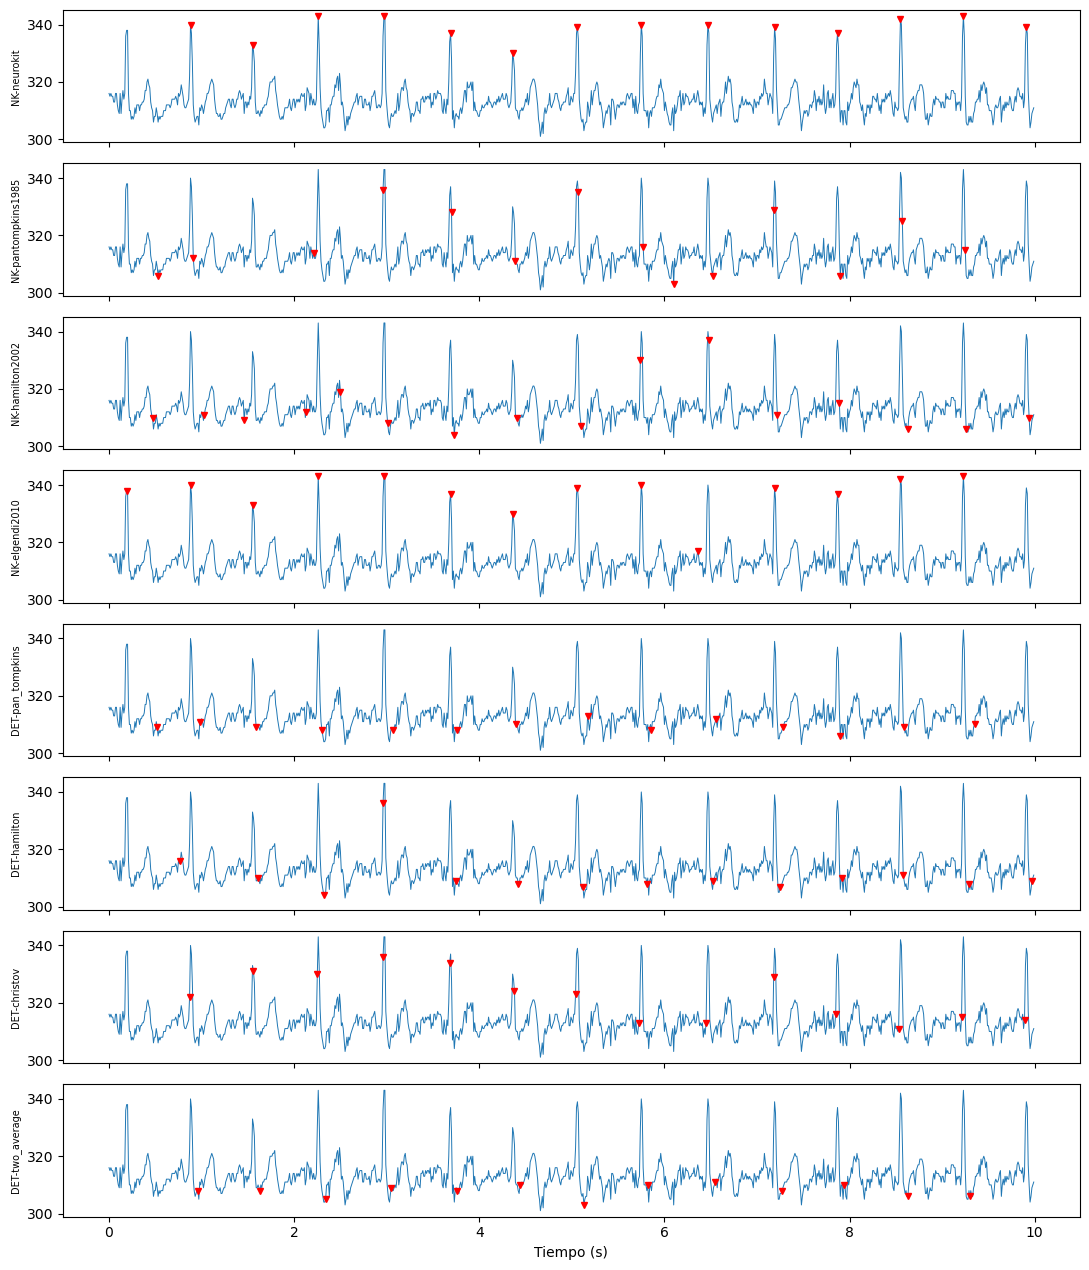

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from ecgdetectors import Detectors
from scipy.signal import find_peaks
from hrvanalysis import get_time_domain_features

fs = 100                      # Hz, frecuencia de muestreo nominal (delay(10) = 10 ms)
ecg = np.loadtxt("ecg.txt")   # 1000 muestras en cuentas del ADC
t = np.arange(len(ecg)) / fs  # eje de tiempo en segundos

picos = {}

# NeuroKit: ecg_peaks devuelve (señales, info); los picos están en info["ECG_R_Peaks"]
for m in ["neurokit", "pantompkins1985", "hamilton2002", "elgendi2010"]:
    _, info = nk.ecg_peaks(ecg, sampling_rate=fs, method=m)
    picos["NK-" + m] = np.asarray(info["ECG_R_Peaks"])

# Detectors: se crea el objeto con fs y cada detector recibe la señal
det = Detectors(fs)
picos["DET-pan_tompkins"] = np.asarray(det.pan_tompkins_detector(ecg))
picos["DET-hamilton"]     = np.asarray(det.hamilton_detector(ecg))
picos["DET-christov"]     = np.asarray(det.christov_detector(ecg))
picos["DET-two_average"]  = np.asarray(det.two_average_detector(ecg))

# Referencia: 15 picos verificados visualmente (umbral = mediana + 15 cuentas, válido para ESTA señal)
ref, _ = find_peaks(ecg, height=np.median(ecg) + 15, distance=40)

def evaluar(p, ref, tol=3):
    tp = sum(np.any(np.abs(ref - q) <= tol) for q in p)
    fp = len(p) - tp
    fn = len(ref) - sum(np.any(np.abs(p - r) <= tol) for r in ref)
    return tp, fp, fn

for nombre, p in picos.items():
    print(f"{nombre:20s} TP/FP/FN = {evaluar(p, ref)}")

# Figura: señal con picos marcados
fig, ax = plt.subplots(len(picos), 1, figsize=(11, 1.6*len(picos)), sharex=True)
for a, (n, p) in zip(ax, picos.items()):
    a.plot(t, ecg, lw=0.7); a.plot(p/fs, ecg[p], "rv", ms=4); a.set_ylabel(n, fontsize=7)
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

Se detectaron los picos R del registro de ECG (1000 muestras, fs nominal = 100 Hz) con dos librerías: cuatro métodos de NeuroKit2 (`neurokit`, `pantompkins1985`, `hamilton2002`, `elgendi2010`) y cuatro detectores de la librería Detectors (`pan_tompkins`, `hamilton`, `christov`, `two_average`).

**Criterio de comparación.** No se dispone de anotaciones de referencia de un especialista, por lo que se tomó como referencia los 15 picos R identificados visualmente en la señal (obtenidos con `find_peaks` y verificados sobre la gráfica). Un pico detectado se consideró acierto (TP) si estaba a ±3 muestras (30 ms) de un pico de referencia; falso positivo (FP) si no correspondía a ninguno; y falso negativo (FN) si un pico de referencia no fue detectado.

| Algoritmo | TP | FP | FN |
|---|---|---|---|
| NeuroKit `neurokit` | 14 | 0 | 1 |
| Detectors `christov` | 14 | 0 | 1 |
| NeuroKit `elgendi2010` | 13 | 1 | 2 |
| NeuroKit `pantompkins1985` | 10 | 4 | 5 |
| NeuroKit `hamilton2002` | 6 | 10 | 9 |
| Detectors `pan_tompkins` | 1 | 13 | 14 |
| Detectors `hamilton` | 2 | 12 | 13 |
| Detectors `two_average` | 0 | 13 | 15 |

**Resultado.** El método `neurokit` detectó 14 de los 15 picos sin falsos positivos (se omitió el primero, ubicado en el borde del registro), y fue el que ubicó los marcadores directamente sobre la cima del complejo QRS (Figura X). `christov` obtuvo el mismo conteo, pero sus marcas quedan desplazadas respecto a la cima. Varios detectores clásicos (Pan-Tompkins, Hamilton, Two-average) fallaron casi por completo, marcando ondas T y valles de la línea base; una posible causa es que fueron diseñados para frecuencias de muestreo mayores que los 100 Hz de este registro (hipótesis por verificar en los artículos originales).

**Conclusión.** En este registro el algoritmo que mejor detecta los picos R es el de **NeuroKit (`neurokit`)**. Esta conclusión se limita a una señal de unos 10 s con una referencia verificada visualmente, por lo que no puede generalizarse.

---

2. Variabilidad de la frecuencia cardíaca (HRV) a partir de los picos R detectados.

R-R (ms): [670, 710, 710, 720, 670, 700, 690, 720, 720, 680, 680, 680, 680]
mean_nni       694.62
sdnn            19.41
sdsd            25.32
nni_50           0.00
pnni_50          0.00
nni_20           5.00
pnni_20         41.67
rmssd           25.33
median_nni     690.00
range_nni       50.00
cvsd             0.04
cvnni            0.03
mean_hr         86.44
max_hr          89.55
min_hr          83.33
std_hr           2.31


<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

...

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

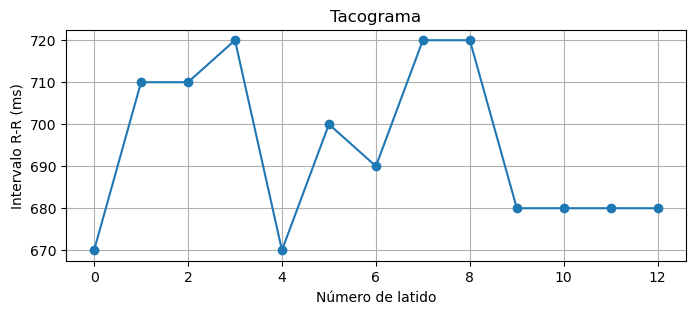

In [12]:
p = picos["NK-neurokit"]               # mejor algoritmo según la celda anterior
rr_ms = list(np.diff(p) / fs * 1000)   # intervalos R-R en milisegundos
print("R-R (ms):", [round(x) for x in rr_ms])

rasgos = get_time_domain_features(rr_ms)   # espera intervalos en ms
for k, v in rasgos.items():
    print(f"{k:12s} {v:8.2f}")

    plt.figure(figsize=(8, 3))
plt.plot(rr_ms, "o-")
plt.xlabel("Número de latido")
plt.ylabel("Intervalo R-R (ms)")
plt.title("Tacograma")
plt.grid(True)
plt.show()

La HRV describe la variación del intervalo de tiempo entre latidos consecutivos. Para calcularla se tomaron los picos R detectados con `neurokit` y se obtuvo la serie de intervalos R-R restando las posiciones de picos consecutivos y convirtiendo de muestras a milisegundos (R-R = Δmuestras / fs × 1000). Se obtuvieron 13 intervalos: 670, 710, 710, 720, 670, 700, 690, 720, 720, 680, 680, 680 y 680 ms, con una media de 694.6 ms (≈ 86.4 lpm). La Figura 3 muestra el tacograma de la serie.

No se aplicó ningún preprocesamiento (eliminación de latidos ectópicos ni interpolación), pues en la inspección visual de la señal no se observaron latidos anómalos.

**REFERENCIAS**

[1] Olimex Ltd., “SHIELD-EKG-EMG.” [En línea]. Disponible: https://www.olimex.com/Products/Duino/Shields/SHIELD-EKG-EMG/
[2] J. G. Webster, Ed., Medical Instrumentation: Application and Design, 4.ª ed. John Wiley & Sons, 2009
